# Online Retail Customer Segmentation Using RFM and K-Means

## Project Overview

This project focuses on analysing customer purchasing behaviour using the Online Retail dataset. The objective is to identify meaningful customer segments using RFM (Recency, Frequency, Monetary) analysis and K-Means clustering.

The analysis builds upon the data preparation and business findings established in the companion Microsoft SQL Server project.

## Business Objectives

1. Analyse customer purchasing behaviour.
2. Calculate Recency, Frequency and Monetary values for each customer.
3. Identify customer groups using K-Means clustering.
4. Understand the purchasing characteristics and revenue contribution of each segment.
5. Develop actionable business recommendations based on customer behaviour.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## Project Workflow

Data Loading → Data Quality Assessment → Data Preparation → Exploratory Data Analysis → RFM Analysis → K-Means Clustering → Customer Segmentation → Business Insights

In [ ]:
# Importing  required libraries
import os
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score,adjusted_rand_score)

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Define dataset path
dataset_path = "/content/drive/MyDrive/09_Datasets/"

In [ ]:
rfm = pd.read_csv(dataset_path + "RFM_Base.csv")
product_sales = pd.read_csv(dataset_path + "Product Sales.csv")
net_sales = pd.read_csv(dataset_path + "Net Sales.csv")

In [ ]:
# Initial dataset overview
print("RFM Base:", rfm.shape)
print("ProductSales:", product_sales.shape)
print("NetSales:", net_sales.shape)
rfm.head()

RFM Base: (4334, 4)
ProductSales: (522537, 9)
NetSales: (531205, 9)


,CustomerID,LastPurchaseDate,Frequency,Monetary
0,12346,2011-01-18 10:01:00.0000000,1,0.00
1,12347,2011-12-07 15:52:00.0000000,7,4310.00
2,12348,2011-09-25 13:13:00.0000000,4,1437.24
3,12349,2011-11-21 09:51:00.0000000,1,1457.55
4,12350,2011-02-02 16:01:00.0000000,1,294.40


In [ ]:
# Convert date columns to datetime
rfm["LastPurchaseDate"] = pd.to_datetime(rfm["LastPurchaseDate"])
product_sales["InvoiceDateTime"] = pd.to_datetime(product_sales["InvoiceDateTime"])
net_sales["InvoiceDateTime"] = pd.to_datetime(net_sales["InvoiceDateTime"])

In [ ]:
# Data Quality and Validation
print("\nRFM VALIDATION")
print("-" * 40)
print("Unique customers:", rfm["CustomerID"].nunique())
print("Duplicate customer IDs:", rfm["CustomerID"].duplicated().sum())
print("Missing values:\n", rfm.isnull().sum())
print("Non-positive Monetary:", (rfm["Monetary"] <= 0).sum())

print("\nTRANSACTION VALIDATION")
print("-" * 40)
print("ProductSales revenue:", round(product_sales["LineRevenue"].sum(), 2))
print("NetSales revenue:", round(net_sales["LineRevenue"].sum(), 2))
print("Cancellation rows:", (net_sales["InvoiceNo"].astype(str).str.startswith("C")).sum())

print("\nRFM PREVIEW")
display(rfm.head())


RFM VALIDATION
----------------------------------------
Unique customers: 4334
Duplicate customer IDs: 0
Missing values:
 CustomerID          0
LastPurchaseDate    0
Frequency           0
Monetary            0
dtype: int64
Non-positive Monetary: 14

TRANSACTION VALIDATION
----------------------------------------
ProductSales revenue: 10247219.32
NetSales revenue: 9771318.16
Cancellation rows: 8668

RFM PREVIEW


,CustomerID,LastPurchaseDate,Frequency,Monetary
0,12346,2011-01-18 10:01:00,1,0.00
1,12347,2011-12-07 15:52:00,7,4310.00
2,12348,2011-09-25 13:13:00,4,1437.24
3,12349,2011-11-21 09:51:00,1,1457.55
4,12350,2011-02-02 16:01:00,1,294.40


##  Exploratory Data Analysis

This section explores the overall business performance, monthly sales trends, leading markets and top-selling products.

In [ ]:
# 1. Overall business overview
business_overview = {
"Total Customers": rfm["CustomerID"].nunique(),
"Purchase Invoices": product_sales["InvoiceNo"].nunique(),
"Distinct Products": product_sales["StockCode"].nunique(),
"Countries": product_sales["Country"].nunique(),
"Positive Sales (£)": product_sales["LineRevenue"].sum(),
"Net Sales (£)": net_sales["LineRevenue"].sum()
}

display(pd.DataFrame.from_dict(business_overview,orient="index",columns=["Value"]).round(2))

,Value
Total Customers,4334.00
Purchase Invoices,19773.00
Distinct Products,3907.00
Countries,38.00
Positive Sales (£),10247219.32
Net Sales (£),9771318.16


,YearMonth,Positive_Sales
0,2010-12,775638.36
1,2011-01,670380.24
2,2011-02,507799.87
3,2011-03,689833.51
4,2011-04,515377.99
5,2011-05,739953.00
6,2011-06,737558.98
7,2011-07,688219.34
8,2011-08,724216.50
9,2011-09,1028320.38


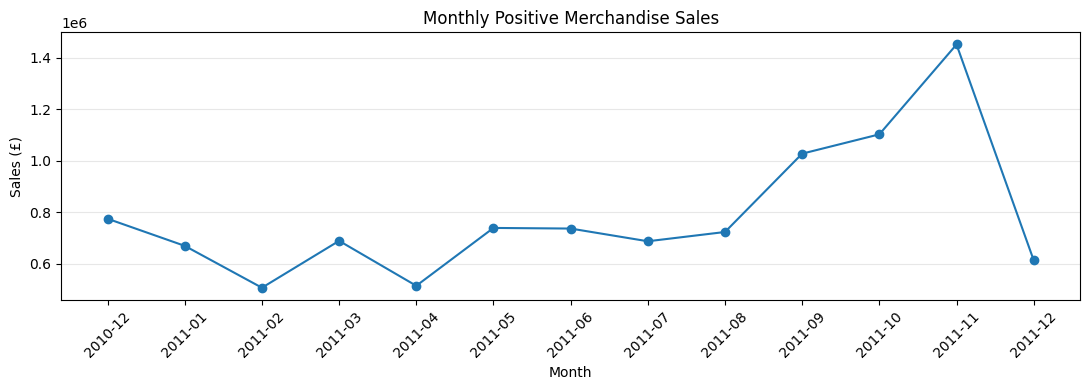

In [ ]:
# 2. Monthly Sales Trend
monthly_sales = (product_sales.assign(YearMonth=product_sales["InvoiceDateTime"].dt.to_period("M").astype(str)).groupby("YearMonth", as_index=False)["LineRevenue"].sum().rename(columns={"LineRevenue": "Positive_Sales"}))
display(monthly_sales.round(2))
plt.figure(figsize=(11, 4))
plt.plot(monthly_sales["YearMonth"],monthly_sales["Positive_Sales"],marker="o")
plt.title("Monthly Positive Merchandise Sales")
plt.xlabel("Month")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 3. Top 10 countries by revenue
top_countries = (product_sales.groupby("Country")["LineRevenue"].sum().sort_values(ascending=False).head(10).reset_index().rename(columns={"LineRevenue": "Positive_Sales"}))
display(top_countries.round(2))

,Country,Positive_Sales
0,United Kingdom,8724443.67
1,Netherlands,283889.34
2,EIRE,270850.86
3,Germany,205381.15
4,France,184493.00
5,Australia,138103.81
6,Spain,55706.56
7,Switzerland,53065.60
8,Japan,37416.37
9,Belgium,36927.34


In [ ]:
# 4. Top 10 products by revenue
top_products = (product_sales.groupby(["StockCode", "Description"])["LineRevenue"].sum().sort_values(ascending=False).head(10).reset_index().rename(columns={"LineRevenue": "Positive_Sales"}))
display(top_products.round(2))

,StockCode,Description,Positive_Sales
0,22423,REGENCY CAKESTAND 3 TIER,174156.54
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
3,47566,PARTY BUNTING,99445.23
4,85099B,JUMBO BAG RED RETROSPOT,94159.81
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,23084,RABBIT NIGHT LIGHT,66870.03
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,79321,CHILLI LIGHTS,54096.36


##  RFM Analysis

This section examines customer purchasing behaviour using three key metrics:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How often a customer made purchases.
- **Monetary:** The customer's net purchase value after accounting for cancellation transactions.

RFM STATISTICAL SUMMARY


,Recency,Frequency,Monetary
count,4334.00,4334.00,4334.00
mean,92.23,4.25,1908.03
std,100.18,7.63,8291.08
min,0.00,1.00,-141.48
25%,17.00,1.00,296.78
50%,50.00,2.00,646.84
75%,142.00,5.00,1600.84
max,373.00,206.00,278778.02



RFM SKEWNESS


,Skewness
Recency,1.243
Frequency,11.949
Monetary,21.575



MONETARY VALIDATION
Customers with Monetary <= 0: 14
Customers with missing Monetary: 0


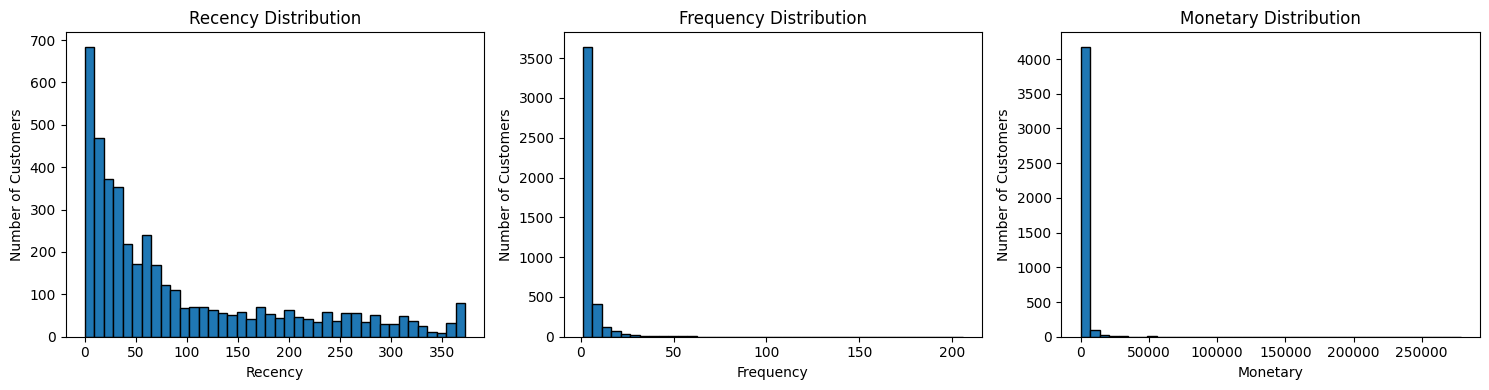

In [ ]:
# Reference date: one day after the last transaction
reference_date = pd.Timestamp("2011-12-10")

# Calculate RFM metrics
rfm["Recency"] = (reference_date - rfm["LastPurchaseDate"]).dt.days

rfm_features = ["Recency", "Frequency", "Monetary"]

# Statistical summary
print("RFM STATISTICAL SUMMARY")
display(rfm[rfm_features].describe().round(2))

# Skewness analysis
print("\nRFM SKEWNESS")
display(rfm[rfm_features].skew().to_frame("Skewness").round(3))

# Monetary validation
print("\nMONETARY VALIDATION")
print("Customers with Monetary <= 0:", (rfm["Monetary"] <= 0).sum())
print("Customers with missing Monetary:", rfm["Monetary"].isna().sum())

# RFM distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, rfm_features):
    ax.hist(rfm[feature], bins=40, edgecolor="black")
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
# Signed log transformation for RFM features
rfm_log = rfm[rfm_features].copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])

rfm_log["Monetary"] = (np.sign(rfm_log["Monetary"])* np.log1p(np.abs(rfm_log["Monetary"])))

# Yeo-Johnson transformation
yeo_transformer = PowerTransformer(method="yeo-johnson",standardize=False)
rfm_yeo = pd.DataFrame(yeo_transformer.fit_transform(rfm[rfm_features]),columns=rfm_features,index=rfm.index)

# Compare skewness across transformations
skew_comparison = pd.DataFrame({"Original": rfm[rfm_features].skew(),"Signed Log": rfm_log.skew(),"Yeo-Johnson": rfm_yeo.skew()})
display(skew_comparison.round(3))

,Original,Signed Log,Yeo-Johnson
Recency,1.243,-0.467,-0.063
Frequency,11.949,1.214,0.219
Monetary,21.575,-0.271,0.471


In [ ]:
transformations = {"Original": rfm[rfm_features],"Signed Log": rfm_log,"Yeo-Johnson": rfm_yeo}
evaluation_results = []

for transformation_name, data in transformations.items():
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)

    for k in range(2, 9):
        model = KMeans(n_clusters=k,random_state=42,n_init=20)
        labels = model.fit_predict(scaled_data)
        evaluation_results.append({
            "Transformation": transformation_name,
            "Clusters": k,
            "Silhouette Score": silhouette_score(scaled_data, labels),
            "Davies-Bouldin Index": davies_bouldin_score(scaled_data, labels),
            "Calinski-Harabasz Score": calinski_harabasz_score(scaled_data, labels)})

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df.round(3))

,Transformation,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Original,2,0.903,0.733,1916.490
1,Original,3,0.591,0.701,3017.654
2,Original,4,0.613,0.674,3199.066
3,Original,5,0.600,0.654,3617.354
4,Original,6,0.599,0.593,3932.189
5,Original,7,0.517,0.629,4239.627
6,Original,8,0.480,0.661,4478.047
7,Signed Log,2,0.431,0.897,4167.441
8,Signed Log,3,0.338,1.045,3423.502
9,Signed Log,4,0.335,1.015,3095.555


In [ ]:
original_scaled = StandardScaler().fit_transform(rfm[rfm_features])

original_profiles = []

for k in [2, 4, 6]:
    model = KMeans(n_clusters=k,random_state=42,n_init=20)
    labels = model.fit_predict(original_scaled)
    profile = rfm[rfm_features].copy()
    profile["Cluster"] = labels
    summary = profile.groupby("Cluster").agg(Customers=("Recency", "count"),Avg_Recency=("Recency", "mean"),Avg_Frequency=("Frequency", "mean"),Avg_Monetary=("Monetary", "mean")).round(2)
    summary["Customer_Share_%"] = (summary["Customers"] / len(rfm) * 100).round(2)
    original_profiles.append((k, summary))

for k, summary in original_profiles:
    print(f"\nOriginal RFM — K={k}")
    display(summary)


Original RFM — K=2


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,
0,4312,92.67,3.89,1491.72,99.49
1,22,5.82,73.68,83503.72,0.51



Original RFM — K=4


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,
0,3146,41.99,4.07,1474.22,72.59
1,1079,247.07,1.54,513.24,24.90
2,6,7.17,75.00,182350.51,0.14
3,103,9.51,33.67,19258.29,2.38



Original RFM — K=6


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,
0,2927,44.52,3.31,1165.75,67.54
1,3,3.00,59.33,242670.28,0.07
2,1065,248.40,1.54,479.05,24.57
3,20,6.60,56.45,54450.91,0.46
4,317,14.81,16.95,7480.94,7.31
5,2,0.50,202.00,79294.12,0.05


In [ ]:
yeo_scaled = StandardScaler().fit_transform(rfm_yeo)

yeo_profiles = []

for k in [3, 4, 5, 6]:

    model = KMeans(n_clusters=k,random_state=42,n_init=20)
    labels = model.fit_predict(yeo_scaled)
    profile = rfm[rfm_features].copy()
    profile["Cluster"] = labels
    summary = profile.groupby("Cluster").agg(Customers=("Recency", "count"),Median_Recency=("Recency", "median"),Median_Frequency=("Frequency", "median"),Median_Monetary=("Monetary", "median"),
     Avg_Recency=("Recency", "mean"),Avg_Frequency=("Frequency", "mean"),Avg_Monetary=("Monetary", "mean")).round(2)
    summary["Customer_Share_%"] = (summary["Customers"] / len(rfm) * 100).round(2)
    yeo_profiles.append((k, summary))

for k, summary in yeo_profiles:
    print(f"\nYeo-Johnson RFM — K={k}")
    display(summary)


Yeo-Johnson RFM — K=3


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,,,,
0,1997,151.0,1.0,306.45,161.97,1.33,423.36,46.08
1,1819,26.0,4.0,1039.30,38.04,4.12,1265.56,41.97
2,518,8.0,12.0,4911.77,13.61,15.94,9887.83,11.95



Yeo-Johnson RFM — K=4


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,,,,
0,1532,17.0,6.0,1964.69,28.45,7.55,2714.68,35.35
1,1345,213.0,1.0,309.40,219.80,1.49,451.02,31.03
2,1399,39.0,2.0,418.40,42.66,1.77,551.95,32.28
3,58,3.5,30.0,28315.48,13.86,40.55,47098.32,1.34



Yeo-Johnson RFM — K=5


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,,,,
0,1169,64.0,3.0,975.23,76.94,3.79,1257.40,26.97
1,993,9.0,7.0,2542.25,12.43,9.34,3501.51,22.91
2,983,31.0,1.0,330.03,34.61,1.39,440.94,22.68
3,1148,232.0,1.0,279.62,229.05,1.22,379.46,26.49
4,41,4.0,33.0,36352.87,11.12,46.93,59840.23,0.95



Yeo-Johnson RFM — K=6


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Share_%
Cluster,,,,,,,,
0,985,9.0,7.0,2514.76,12.51,9.11,3347.07,22.73
1,1152,232.0,1.0,283.52,228.77,1.23,387.01,26.58
2,1157,64.0,3.0,982.07,76.30,3.81,1246.06,26.70
3,53,3.0,30.0,30175.82,14.04,42.21,50133.93,1.22
4,985,31.0,1.0,329.36,34.81,1.39,434.66,22.73
5,2,261.5,1.5,-118.70,261.50,1.50,-118.70,0.05


In [ ]:
business_comparison = []

for k in [3, 5]:
    model = KMeans(n_clusters=k,random_state=42,n_init=20)
    labels = model.fit_predict(yeo_scaled)
    profile = rfm[rfm_features].copy()
    profile["Cluster"] = labels
    summary = profile.groupby("Cluster").agg(Customers=("Recency", "count"), Median_Recency=("Recency", "median"),Median_Frequency=("Frequency", "median"),Median_Monetary=("Monetary", "median"),Net_Monetary_Contribution=("Monetary", "sum"))
    summary["Customer_Share_%"] = (summary["Customers"] / len(rfm) * 100)
    summary["Net_Monetary_Contribution_Pct"] = (summary["Net_Monetary_Contribution"]/ rfm["Monetary"].sum() * 100)

    summary["K"] = k
    business_comparison.append(summary.reset_index())

business_comparison = pd.concat(business_comparison, ignore_index=True)
business_comparison = business_comparison.sort_values(["K", "Cluster"])[["K","Cluster","Customers","Customer_Share_%","Median_Recency","Median_Frequency","Median_Monetary","Net_Monetary_Contribution", "Net_Monetary_Contribution_Pct"]]
display(business_comparison.round(2))

,K,Cluster,Customers,Customer_Share_%,Median_Recency,Median_Frequency,Median_Monetary,Net_Monetary_Contribution,Net_Monetary_Contribution_Pct
0,3,0,1997,46.08,151.0,1.0,306.45,845440.96,10.22
1,3,1,1819,41.97,26.0,4.0,1039.30,2302062.08,27.84
2,3,2,518,11.95,8.0,12.0,4911.77,5121896.87,61.94
3,5,0,1169,26.97,64.0,3.0,975.23,1469896.84,17.78
4,5,1,993,22.91,9.0,7.0,2542.25,3476996.34,42.05
5,5,2,983,22.68,31.0,1.0,330.03,433440.36,5.24
6,5,3,1148,26.49,232.0,1.0,279.62,435616.84,5.27
7,5,4,41,0.95,4.0,33.0,36352.87,2453449.53,29.67


In [ ]:
## Train the final K-Means model
final_model = KMeans(n_clusters=5,random_state=42,n_init=20)
rfm["Cluster"] = final_model.fit_predict(yeo_scaled)

# Assign business segment names
segment_mapping = {
0: "Regular Customers",
1: "High-Value Active Customers",
2: "Recent One-Time Customers",
3: "Lapsed Customers",
4: "VIP Customers"
}

rfm["Customer_Segment"] = rfm["Cluster"].map(segment_mapping)

# Create final customer segment profile
final_profile = rfm.groupby("Customer_Segment").agg(
Customers=("Recency", "count"),
Median_Recency=("Recency", "median"),
Median_Frequency=("Frequency", "median"),
Median_Monetary=("Monetary", "median"),
Avg_Recency=("Recency", "mean"),
Avg_Frequency=("Frequency", "mean"),
Avg_Monetary=("Monetary", "mean"),
Net_Monetary_Contribution=("Monetary", "sum")
)

final_profile["Customer_Share_%"] = (final_profile["Customers"] / len(rfm) * 100)
final_profile["Net_Monetary_Contribution_Pct"] = (final_profile["Net_Monetary_Contribution"]/ rfm["Monetary"].sum() * 100)
display(final_profile.round(2))

,Customers,Median_Recency,Median_Frequency,Median_Monetary,Avg_Recency,Avg_Frequency,Avg_Monetary,Net_Monetary_Contribution,Customer_Share_%,Net_Monetary_Contribution_Pct
Customer_Segment,,,,,,,,,,
High-Value Active Customers,993,9.0,7.0,2542.25,12.43,9.34,3501.51,3476996.34,22.91,42.05
Lapsed Customers,1148,232.0,1.0,279.62,229.05,1.22,379.46,435616.84,26.49,5.27
Recent One-Time Customers,983,31.0,1.0,330.03,34.61,1.39,440.94,433440.36,22.68,5.24
Regular Customers,1169,64.0,3.0,975.23,76.94,3.79,1257.40,1469896.84,26.97,17.78
VIP Customers,41,4.0,33.0,36352.87,11.12,46.93,59840.23,2453449.53,0.95,29.67


In [ ]:
# Reference labels from the final model
reference_labels = final_model.labels_

# Test different random seeds
seeds = [10, 20, 30, 40, 50, 100]
stability_scores = []

for seed in seeds:
    model = KMeans( n_clusters=5, random_state=seed,n_init=20)
    labels = model.fit_predict(yeo_scaled)
    score = adjusted_rand_score(reference_labels,labels)
    stability_scores.append({"Random_Seed": seed,"Adjusted_Rand_Index": score})

stability_df = pd.DataFrame(stability_scores)
display(stability_df.round(4))
print("Average ARI:",round(stability_df["Adjusted_Rand_Index"].mean(), 4))

,Random_Seed,Adjusted_Rand_Index
0,10,0.9987
1,20,0.9969
2,30,0.9956
3,40,0.9991
4,50,0.9969
5,100,0.9979


Average ARI: 0.9975


## Model Selection and Validation

### Feature Transformation
The original RFM variables showed substantial positive skewness, particularly Frequency and Monetary. Yeo-Johnson transformation was selected because it reduces skewness while supporting zero and negative values in Monetary.

### Cluster Selection
K-Means models were evaluated across cluster counts from 2 to 8 using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.

Although K=3 achieved a slightly higher Silhouette Score (0.375) than K=5 (0.363), the five-cluster solution provided more meaningful business segmentation.

### Final Model
The selected model uses:
- Yeo-Johnson feature transformation
- StandardScaler
- K-Means clustering
- 5 clusters
- Random state: 42
- 20 initializations (`n_init=20`)

### Stability Validation
The model achieved an average Adjusted Rand Index (ARI) of 0.9975 across six alternative random seeds, indicating highly consistent clustering assignments under different initializations.

**Limitation:** This test evaluates initialization consistency only. It does not establish stability across different samples or time periods.

### Business Relevance
The five-cluster solution identifies distinct customer groups, including VIP and High-Value Active Customers, enabling more targeted customer retention and engagement strategies.

In [ ]:
output_path = (
"/content/drive/MyDrive/03_Career/02_Projects/"
"Online_Retail_Customer_Segmentation/"
"RFM_Segmented.csv"
)

rfm.to_csv(output_path, index=False)
print("Segmented RFM dataset saved successfully.")

In [ ]:
print("File location:", output_path)
print("Total customers:", len(rfm))
print("Total segments:", rfm["Customer_Segment"].nunique())

File location: /content/drive/MyDrive/03_Career/02_Projects/Online_Retail_Customer_Segmentation/RFM_Segmented.csv
Total customers: 4334
Total segments: 5


In [ ]:
rfm

,CustomerID,LastPurchaseDate,Frequency,Monetary,Recency,Cluster,Customer_Segment
0,12346,2011-01-18 10:01:00,1,0.00,325,3,Lapsed Customers
1,12347,2011-12-07 15:52:00,7,4310.00,2,1,High-Value Active Customers
2,12348,2011-09-25 13:13:00,4,1437.24,75,0,Regular Customers
3,12349,2011-11-21 09:51:00,1,1457.55,18,2,Recent One-Time Customers
4,12350,2011-02-02 16:01:00,1,294.40,310,3,Lapsed Customers
...,...,...,...,...,...,...,...
4329,18280,2011-03-07 09:52:00,1,180.60,277,3,Lapsed Customers
4330,18281,2011-06-12 10:53:00,1,80.82,180,3,Lapsed Customers
4331,18282,2011-12-02 11:43:00,2,176.60,7,2,Recent One-Time Customers
4332,18283,2011-12-06 12:02:00,16,2039.58,3,1,High-Value Active Customers


##  Customer Segmentation Visualisation

This section visualises the distribution, purchasing behaviour and
business contribution of the five customer segments.

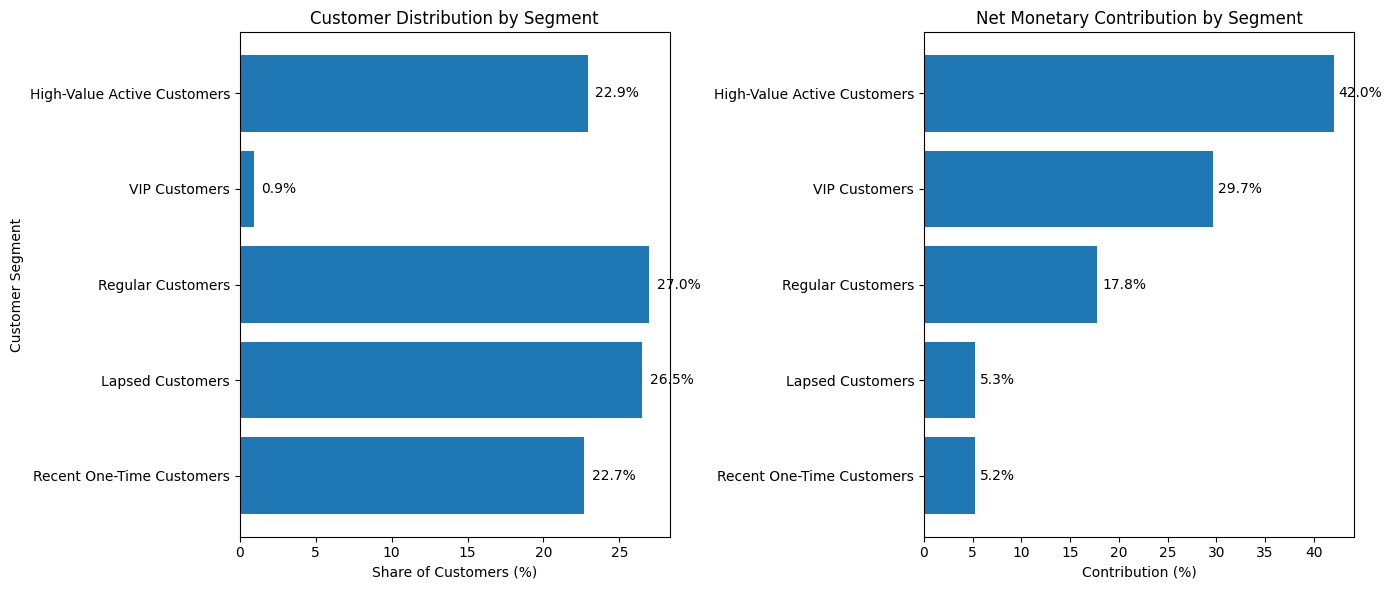

In [ ]:
# Compare customer distribution and net monetary contribution

segment_data = final_profile.sort_values("Net_Monetary_Contribution_Pct",ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Customer distribution
axes[0].barh(segment_data.index,segment_data["Customer_Share_%"])
axes[0].set_title("Customer Distribution by Segment")
axes[0].set_xlabel("Share of Customers (%)")
axes[0].set_ylabel("Customer Segment")

# Net monetary contribution
axes[1].barh(segment_data.index,segment_data["Net_Monetary_Contribution_Pct"])
axes[1].set_title("Net Monetary Contribution by Segment")
axes[1].set_xlabel("Contribution (%)")
axes[1].set_ylabel("")

# Add percentage labels
for ax in axes:
    for bar in ax.patches:
        width = bar.get_width()
        ax.text(width + 0.5,bar.get_y() + bar.get_height() / 2,f"{width:.1f}%",va="center")
plt.tight_layout()
plt.show()

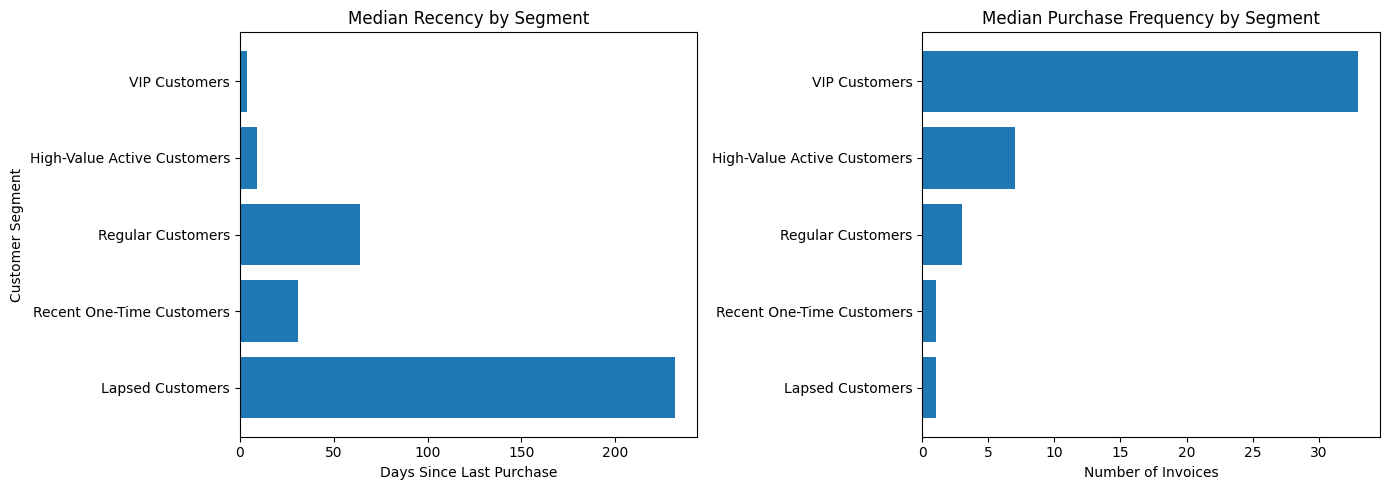

In [ ]:
# Compare median Recency and Frequency across customer segments

segment_data = final_profile.sort_values("Median_Frequency")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Median Recency
axes[0].barh(segment_data.index,segment_data["Median_Recency"])
axes[0].set_title("Median Recency by Segment")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Customer Segment")

# Median Frequency
axes[1].barh(segment_data.index,segment_data["Median_Frequency"])
axes[1].set_title("Median Purchase Frequency by Segment")
axes[1].set_xlabel("Number of Invoices")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

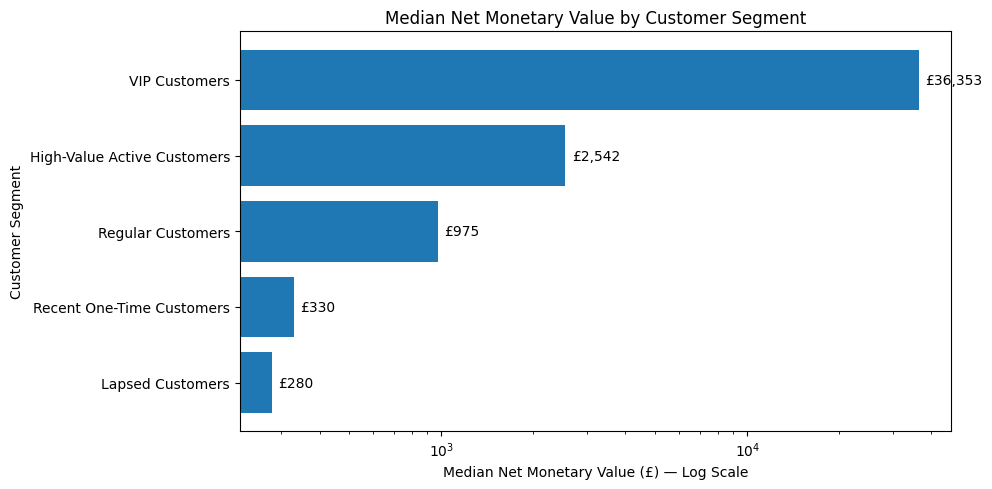

In [ ]:
# Compare median monetary value across customer segments

segment_data = final_profile.sort_values("Median_Monetary")
plt.figure(figsize=(10, 5))
bars = plt.barh(segment_data.index,segment_data["Median_Monetary"])
plt.xscale("log")
plt.title("Median Net Monetary Value by Customer Segment")
plt.xlabel("Median Net Monetary Value (£) — Log Scale")
plt.ylabel("Customer Segment")

for bar in bars:
    value = bar.get_width()
    plt.text(value * 1.05,bar.get_y() + bar.get_height() / 2, f"£{value:,.0f}",va="center")
plt.tight_layout()
plt.show()

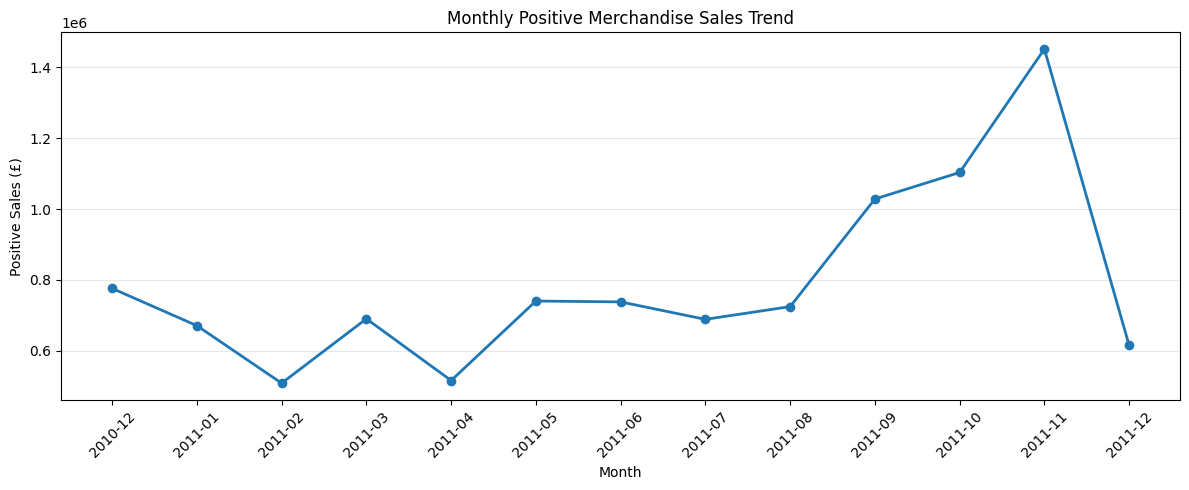

In [ ]:
# Monthly positive merchandise sales trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["YearMonth"],monthly_sales["Positive_Sales"],marker="o",linewidth=2)
plt.title("Monthly Positive Merchandise Sales Trend")
plt.xlabel("Month")
plt.ylabel("Positive Sales (£)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Business Insights and Recommendations

### Key Business Insights

**1. VIP Customers — High Revenue Concentration**

- VIP customers represent only 0.95% of the customer base.
- They contribute 29.67% of total net monetary value.
- Their median purchase frequency is 33 invoices.

**Business implication:** The business has a small group of exceptionally valuable customers. Losing even a few could have a disproportionate impact on revenue.

**2. High-Value Active Customers — Core Revenue Segment**

- This segment represents 22.91% of customers.
- It contributes 42.05% of total net monetary value.
- Median recency is 9 days, with a median frequency of 7 invoices.

**Business implication:** These customers are recently active and generate the largest share of monetary value. Retention should be a priority.

**3. Regular Customers — Retention Opportunity**

- Regular customers represent 26.97% of the customer base.
- They contribute 17.78% of total net monetary value.
- Their median frequency is 3 invoices.

**Business implication:** Encourage repeat purchases through relevant product recommendations and targeted promotions.

**4. Recent One-Time Customers — Conversion Opportunity**

- This segment represents 22.68% of customers.
- It contributes 5.24% of total net monetary value.
- Median purchase frequency is 1 invoice.

**Business implication:** Encourage a second purchase through follow-up campaigns, product recommendations and carefully targeted incentives.

**5. Lapsed Customers — Reactivation Opportunity**

- Lapsed customers represent 26.49% of the customer base.
- They contribute only 5.27% of total net monetary value.
- Their median recency is 232 days.

**Business implication:** Test reactivation campaigns to identify customers who can be brought back profitably.

### Recommended Business Actions

| Customer Segment | Recommended Action |
|---|---|
| VIP Customers | Loyalty benefits and personalised retention |
| High-Value Active | Priority service and cross-selling |
| Regular Customers | Repeat-purchase campaigns |
| Recent One-Time | Second-purchase incentives |
| Lapsed Customers | Targeted win-back campaigns |

### Project Limitations

- The analysis uses historical transactions from a single dataset covering approximately one year.
- Customer segments reflect purchasing behaviour at a fixed reference date of 10 December 2011.
- Monetary values are calculated by aggregating eligible sales and cancellation lines at customer level; exact original-order cancellation matching is not established.
- K-Means clustering is sensitive to feature transformations and the selected number of clusters.
- Stability testing evaluates consistency across random initialisation seeds, not stability across different time periods or customer samples.
- Recommended campaigns are hypotheses and should be tested before drawing conclusions about their effectiveness.